# LSMO / STO (001): φ scan analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

file_phi = "3_Phi_Scan_LSMO.ras"   # phi scan

## Helper functions

In [2]:
def read_ras(path):
    # Return (header dict, DataFrame[angle, intensity, atten]) from a Rigaku .ras file
    header, data = {}, []
    in_data = False
    with open(path, "r", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if line.startswith("*RAS_INT_START"):
                in_data = True
                continue
            if line.startswith("*RAS_INT_END"):
                in_data = False
                continue
            if in_data:
                parts = line.split()
                if len(parts) >= 2:
                    data.append([float(p) for p in parts[:3]])
            elif line.startswith("*") and " " in line:
                key, val = line[1:].split(" ", 1)
                header[key] = val.strip().strip('"')
    cols = ["angle", "intensity", "atten"][:len(data[0])]
    return header, pd.DataFrame(data, columns=cols)

def axis_position(header, name):
    # Value of a named goniometer axis (e.g. Chi, TwoTheta, Omega) from the header
    for k, v in header.items():
        if k.startswith("MEAS_COND_AXIS_NAME-") and v == name:
            return header.get("MEAS_COND_AXIS_POSITION-" + k.split("-")[1])

def pseudo_voigt(x, A, x0, w, eta, b):
    g = np.exp(-4*np.log(2)*((x - x0)/w)**2)
    l = 1/(1 + 4*((x - x0)/w)**2)
    return A*(eta*l + (1 - eta)*g) + b

## φ scan: load and plot

(36001, 3)
MEAS_SCAN_AXIS_X        : Phi
MEAS_SCAN_START         : 0.000
MEAS_SCAN_STOP          : 360.000
MEAS_SCAN_STEP          : 0.010
MEAS_SCAN_SPEED         : 10.000
MEAS_SCAN_SPEED_UNIT    : deg/min
fixed 2theta = 39.7825 deg, omega = 19.8912 deg, chi = 54.736 deg


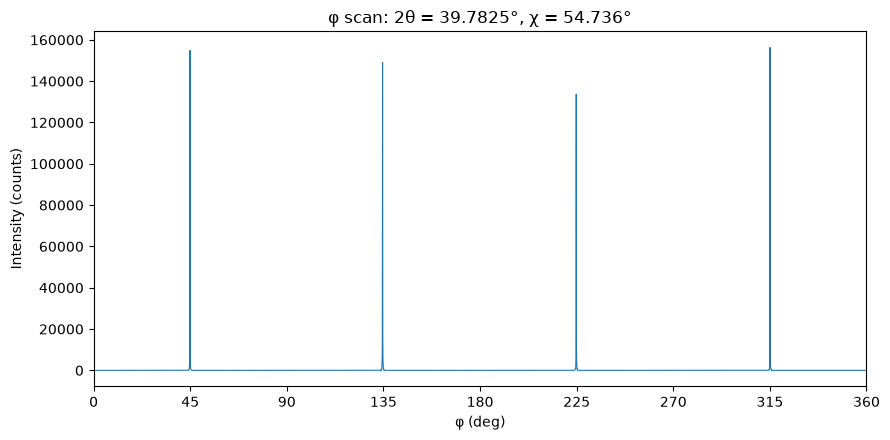

In [3]:
hdr2, df2 = read_ras(file_phi)
phi, I = df2["angle"].values, df2["intensity"].values
tth, om, chi = (float(axis_position(hdr2, n)) for n in ["TwoTheta", "Omega", "Chi"])

print(df2.shape)
for k in ["MEAS_SCAN_AXIS_X", "MEAS_SCAN_START", "MEAS_SCAN_STOP", "MEAS_SCAN_STEP",
          "MEAS_SCAN_SPEED", "MEAS_SCAN_SPEED_UNIT"]:
    print(f"{k:24s}: {hdr2.get(k)}")
print(f"fixed 2theta = {tth} deg, omega = {om} deg, chi = {chi} deg")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(phi, I, lw=0.8)
ax.set_xlabel("φ (deg)"); ax.set_ylabel("Intensity (counts)")
ax.set_title(f"φ scan: 2θ = {tth}°, χ = {chi}°")
ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 45))
plt.tight_layout(); 
# plt.savefig("lsmo_phi_scan.png", dpi=300); plt.show()

,phi (deg),err (deg),FWHM (deg),peak counts,spacing to previous (deg)
0,44.894,0.0,0.098,154876.250,NaN
1,134.584,0.0,0.100,149098.109,89.690
2,224.794,0.0,0.083,133665.641,90.210
3,315.070,0.0,0.063,156308.812,90.276


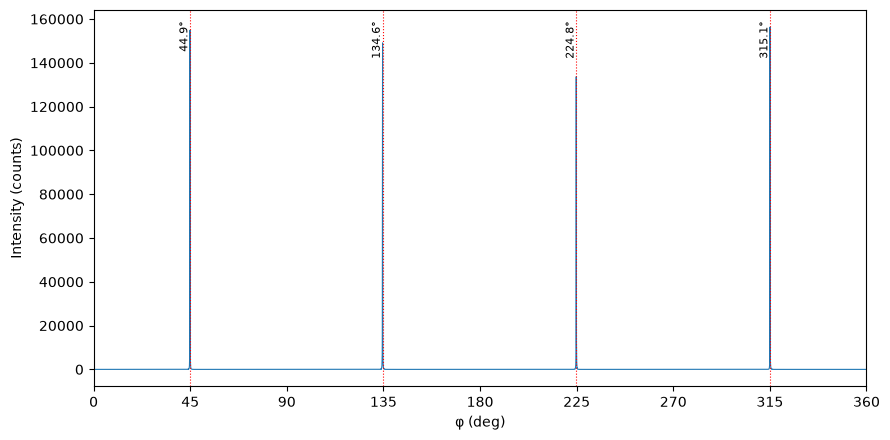

In [4]:
# Locate peaks (1 deg smoothing), then fit each with a pseudo-Voigt in a +-3 deg window
ys = pd.Series(I).rolling(101, center=True, min_periods=1).mean().values
idx, _ = find_peaks(ys, prominence=0.05*ys.max(), distance=int(30/0.01))

rows = []
for i in idx:
    m = abs(phi - phi[i]) < 3
    p, cov = curve_fit(pseudo_voigt, phi[m], I[m], p0=[I[i], phi[i], 0.15, 0.5, 0],
                       bounds=([0, phi[i]-3, 0.01, 0, 0], [1e7, phi[i]+3, 3, 1, 1e4]))
    rows.append({"phi (deg)": p[1], "err (deg)": np.sqrt(np.diag(cov))[1],
                 "FWHM (deg)": p[2], "peak counts": I[m].max()})
phi_peaks = pd.DataFrame(rows).round(3)
phi_peaks["spacing to previous (deg)"] = phi_peaks["phi (deg)"].diff().round(3)
display(phi_peaks)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(phi, I, lw=0.8)
for p in phi_peaks["phi (deg)"]:
    ax.axvline(p, color="r", ls=":", lw=0.8)
    ax.text(p, ax.get_ylim()[1]*0.97, f"{p:.1f}°", rotation=90, ha="right", va="top", fontsize=8)
ax.set_xlabel("φ (deg)"); ax.set_ylabel("Intensity (counts)")
ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 45))
plt.tight_layout(); plt.savefig("lsmo_phi_peaks.png", dpi=300); plt.show()

In [5]:
# Symmetry and epitaxy checks
n = len(phi_peaks)
pos = phi_peaks["phi (deg)"].values
spacing = np.diff(pos)
fold = 360.0/np.mean(np.r_[spacing, 360 - (pos[-1] - pos[0])])

# Any additional (e.g. rotated-domain) peaks? Mask +-5 deg around the main peaks.
mask = np.ones_like(phi, bool)
for p in pos:
    mask &= abs(phi - p) > 5
bg_mean, bg_max = I[mask].mean(), I[mask].max()
weakest = phi_peaks["peak counts"].min()

print(f"Number of peaks in 360 deg      : {n}  ->  {fold:.0f}-fold symmetry")
print(f"Peak spacings                   : {np.round(spacing, 2)} deg (ideal 90)")
print(f"Max deviation from 90 deg       : {np.max(np.abs(spacing - 90)):.2f} deg")
print(f"Peak FWHM                       : {phi_peaks['FWHM (deg)'].min():.2f} - {phi_peaks['FWHM (deg)'].max():.2f} deg")
print(f"Peak intensity spread           : {phi_peaks['peak counts'].min():.0f} - {phi_peaks['peak counts'].max():.0f} counts")
print(f"Background between peaks        : mean {bg_mean:.2f}, max {bg_max:.1f} counts")
print(f"Weakest peak / background max   : {weakest/bg_max:.1e}")
print(f"chi = {chi}° vs. angle between (001) and (111) = {np.degrees(np.arccos(1/np.sqrt(3))):.2f}° -> {{111}}-type reflection")

Number of peaks in 360 deg      : 4  ->  4-fold symmetry
Peak spacings                   : [89.69 90.21 90.28] deg (ideal 90)
Max deviation from 90 deg       : 0.31 deg
Peak FWHM                       : 0.06 - 0.10 deg
Peak intensity spread           : 133666 - 156309 counts
Background between peaks        : mean 0.28, max 5.2 counts
Weakest peak / background max   : 2.6e+04
chi = 54.736° vs. angle between (001) and (111) = 54.74° -> {111}-type reflection
